# How do the groups change with the minimum mirror count?

Rebuild the same graph with minimum counts of 20, 30 and 50 opposite-side, same-stake-bucket matches. The current audit uses 30. Round construction, tier rules and the shared-round denominator stay fixed. The query starts at 20 so the higher thresholds can use subsets of the same pair statistics.

In [1]:
%matplotlib inline
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from rings import classify_pairs, connected_groups

con = duckdb.connect("../private/wagers.duckdb", read_only=True,
                     config={"threads": 4, "memory_limit": "3GB",
                             "temp_directory": "../private/audit-spill"})

con.execute("SET VARIABLE min_mirrors = 20")
con.execute(Path("compare_pairs.sql").read_text())
pairs = classify_pairs(con.sql("SELECT * FROM pair_metrics").df())
con.close()

,Candidate pairs,Retained links,Accounts,Groups,Largest group,Baseline accounts retained
Minimum mirrors,,,,,,
20,17633,194,208,41,90,192
30,7276,182,192,36,87,192
50,2303,144,155,26,83,155


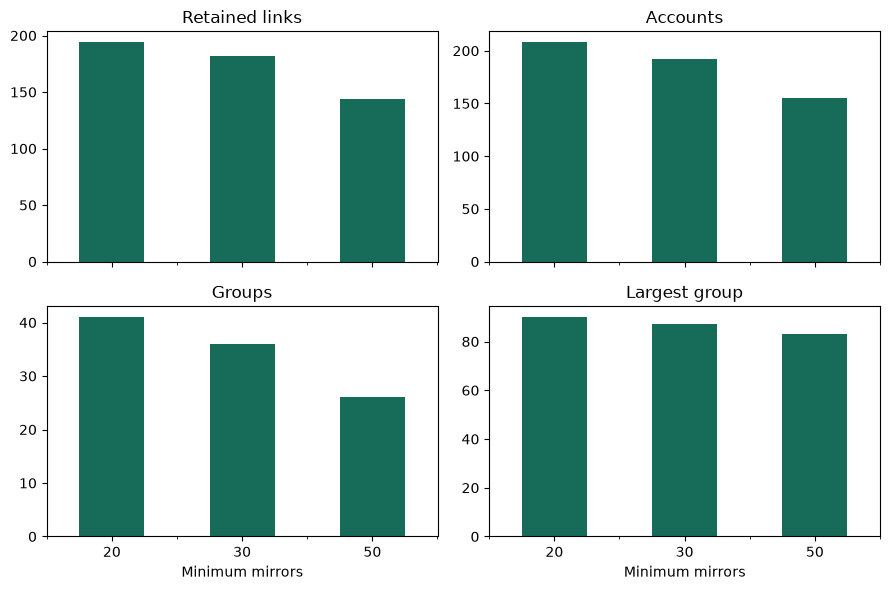

In [2]:
baseline = pairs[(pairs.mirrored >= 30) & pairs.tier.isin(["A", "B"])]
baseline_accounts = set(baseline.account_a) | set(baseline.account_b)
rows = []
for minimum in (20, 30, 50):
    candidates = pairs[pairs.mirrored >= minimum]
    links = candidates[candidates.tier.isin(["A", "B"])]
    groups = connected_groups(links)
    accounts = set(links.account_a) | set(links.account_b)
    rows.append({"Minimum mirrors": minimum, "Candidate pairs": len(candidates),
                 "Retained links": len(links), "Accounts": len(accounts),
                 "Groups": len(groups), "Largest group": max(map(len, groups), default=0),
                 "Baseline accounts retained": len(accounts & baseline_accounts)})
summary = pd.DataFrame(rows).set_index("Minimum mirrors")
assert tuple(summary.loc[30, ["Retained links", "Accounts", "Groups"]]) == (182, 192, 36)
display(summary)
axes = summary[["Retained links", "Accounts", "Groups", "Largest group"]].plot.bar(
    subplots=True, layout=(2, 2), figsize=(9, 6), rot=0, legend=False,
    title=["Retained links", "Accounts", "Groups", "Largest group"],
    color="#176c59", sharex=True)
for ax in axes.ravel():
    ax.set_xlabel("Minimum mirrors")
plt.tight_layout()
plt.show()

Higher thresholds can drop short-lived links or split a connected group when a bridging link disappears. This experiment changes one rule at a time. It measures stability under mirror-count choices. Operator pooling and the timestamp rule remain separate assumptions.